<a href="https://colab.research.google.com/github/saraalmazroa/-IT326-DataMining-Project-/blob/main/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Phase 3**

In [ ]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [ ]:
# Load data
url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/Preprocessed_data.csv"
df = pd.read_csv(url, index_col=0)   # index_col=0 removes the extra "Unnamed: 0" column
print(df.head())   # get the first 5 rows

                 Age     Sex  Job Housing Saving accounts Checking account  \
Unnamed: 0                                                                   
0           1.000000    male    2     own          little           little   
1           0.065934  female    2     own          little         moderate   
2           0.659341    male    1     own          little           little   
3           0.571429    male    2    free          little           little   
4           0.747253    male    2    free          little           little   

            Credit amount  Duration              Purpose  Risk  \
Unnamed: 0                                                       
0                0.120408  0.052632             radio/TV  good   
1                0.746950  1.000000             radio/TV   bad   
2                0.241864  0.210526            education  good   
3                0.999951  1.000000  furniture/equipment  good   
4                0.605316  0.526316                  car 

## Classification – Gini Index: 90% training / 10% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)   # 90% training and 10% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_90 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_90 = clf_90.fit(X_train_90, y_train_90)

# Predict the response for test dataset
y_pred_90 = clf_90.predict(X_test_90)

# Model Accuracy, how often is the classifier correct?
acc_90 = metrics.accuracy_score(y_test_90, y_pred_90)
print("Accuracy:", acc_90)

Accuracy: 0.64


### Confusion matrix (90/10)


[[13 17]
 [19 51]]


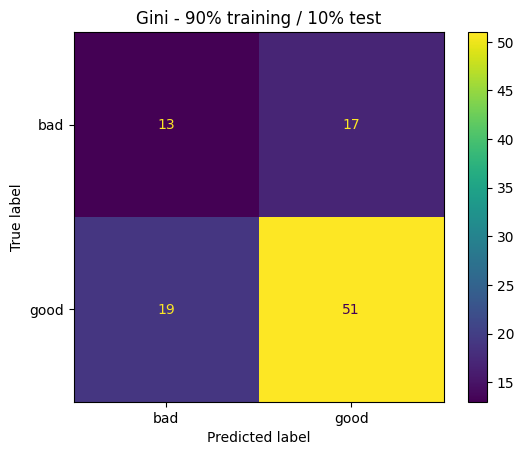

In [ ]:
# Compute and print the confusion matrix
cm_90 = confusion_matrix(y_test_90, y_pred_90)
print(cm_90)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_90, X_test_90, y_test_90, display_labels=cn)
plt.title("Gini - 90% training / 10% test")
plt.show()

### Decision tree plot (90/10)


Accuracy of the pruned tree (for the plot only): 0.7


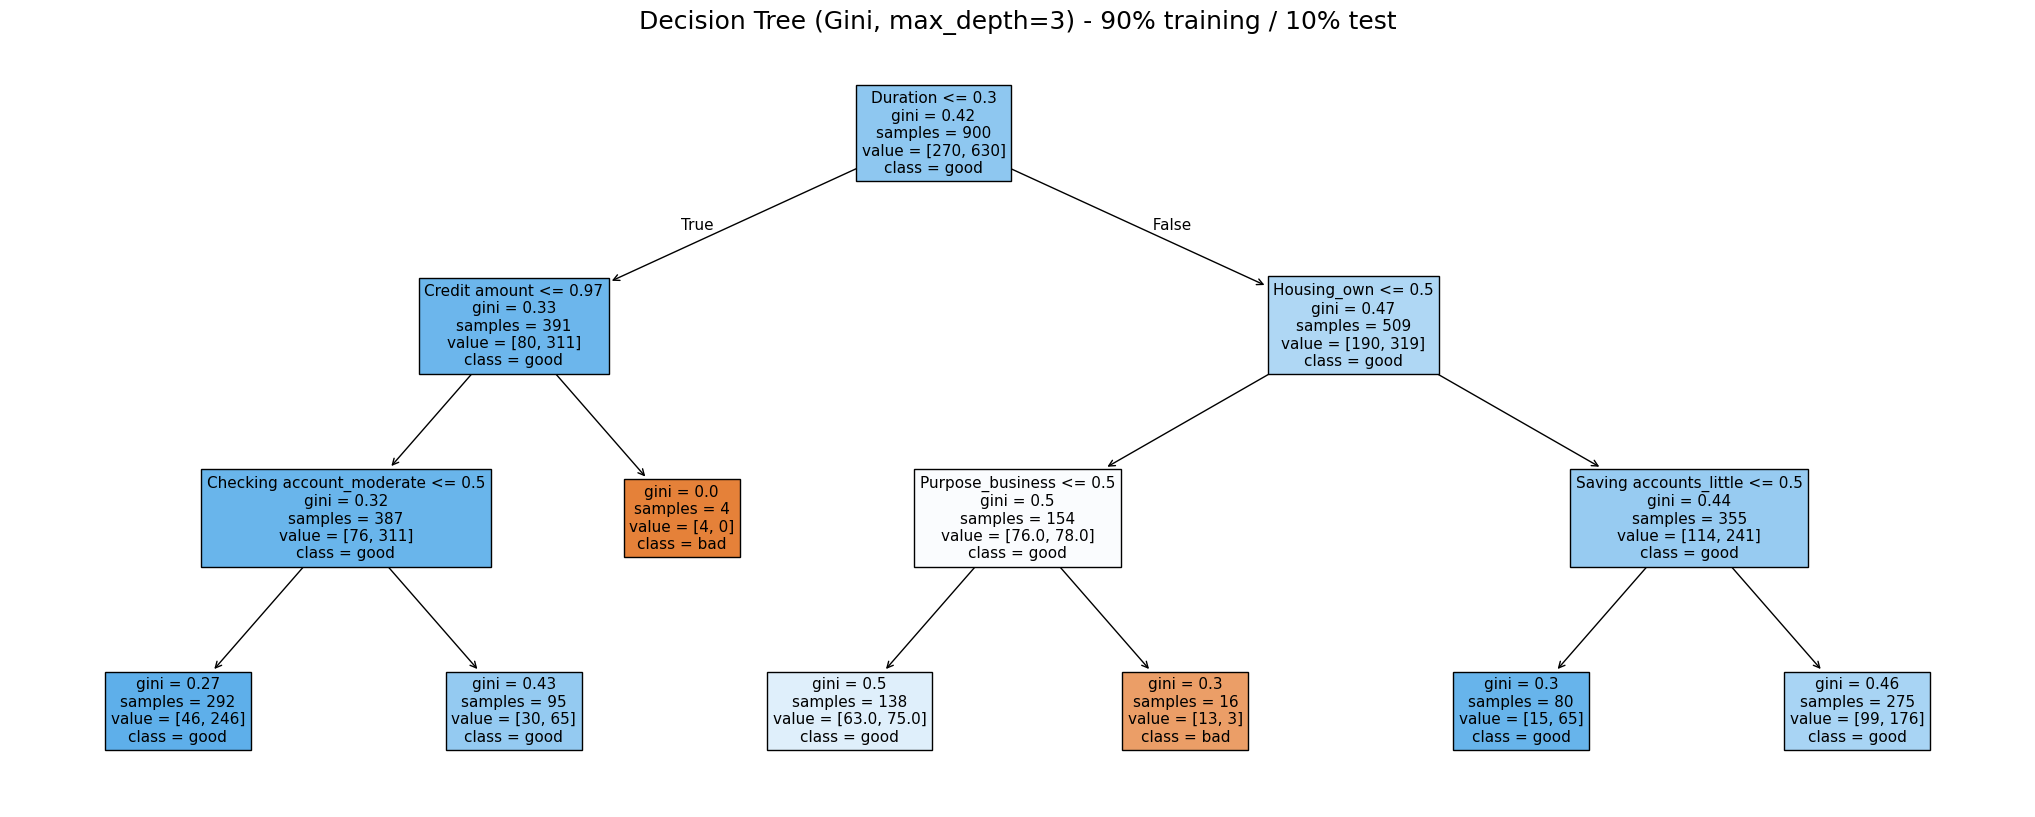

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_90_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_90_plot = clf_90_plot.fit(X_train_90, y_train_90)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_90, clf_90_plot.predict(X_test_90)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_90_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 90% training / 10% test", fontsize=18)
fig.savefig('gini_DT_90_10.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 80% training / 20% testing


In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)   # 80% training and 20% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_80 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_80 = clf_80.fit(X_train_80, y_train_80)

# Predict the response for test dataset
y_pred_80 = clf_80.predict(X_test_80)

# Model Accuracy, how often is the classifier correct?
acc_80 = metrics.accuracy_score(y_test_80, y_pred_80)
print("Accuracy:", acc_80)

Accuracy: 0.66


### Confusion matrix (80/20)


[[ 26  33]
 [ 35 106]]


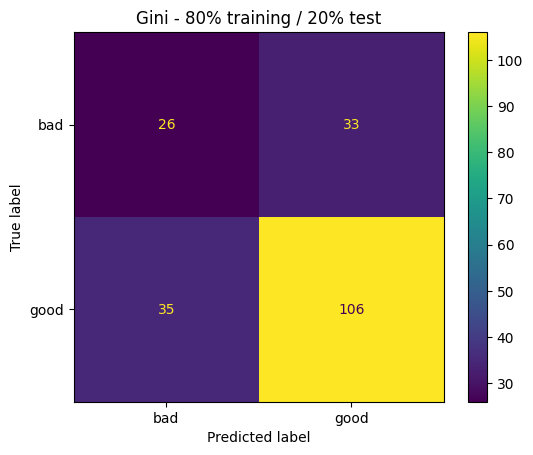

In [ ]:
# Compute and print the confusion matrix
cm_80 = confusion_matrix(y_test_80, y_pred_80)
print(cm_80)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_80, X_test_80, y_test_80, display_labels=cn)
plt.title("Gini - 80% training / 20% test")
plt.show()

### Decision tree plot (80/20)


Accuracy of the pruned tree (for the plot only): 0.71


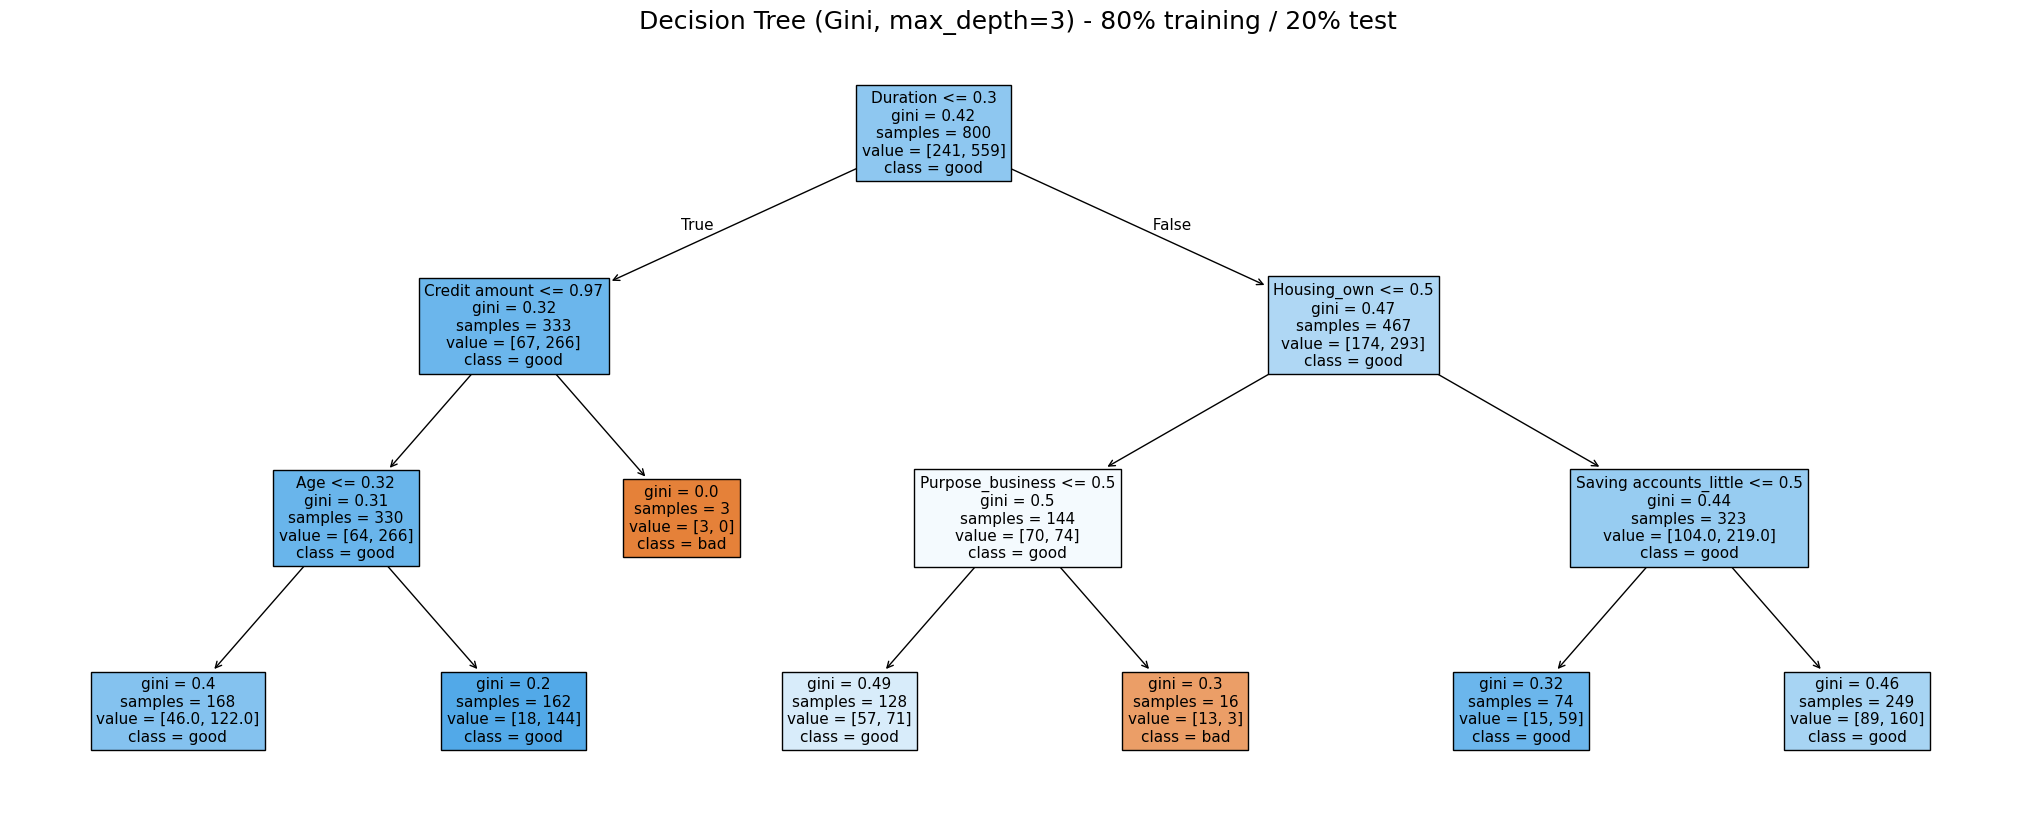

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_80_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_80_plot = clf_80_plot.fit(X_train_80, y_train_80)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_80, clf_80_plot.predict(X_test_80)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_80_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 80% training / 20% test", fontsize=18)
fig.savefig('gini_DT_80_20.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 70% training / 30% testing


In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)   # 70% training and 30% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_70 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_70 = clf_70.fit(X_train_70, y_train_70)

# Predict the response for test dataset
y_pred_70 = clf_70.predict(X_test_70)

# Model Accuracy, how often is the classifier correct?
acc_70 = metrics.accuracy_score(y_test_70, y_pred_70)
print("Accuracy:", acc_70)

Accuracy: 0.6233333333333333


### Confusion matrix (70/30)


[[ 34  52]
 [ 61 153]]


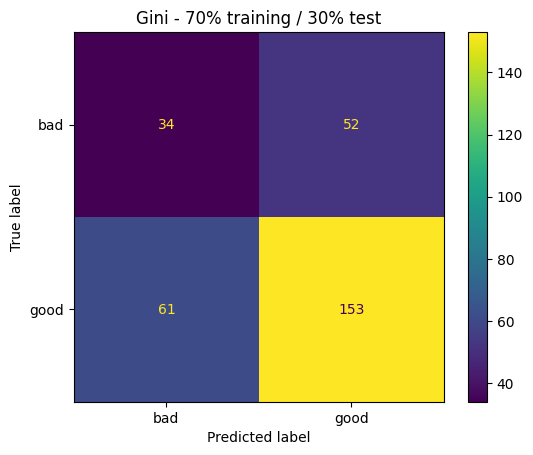

In [ ]:
# Compute and print the confusion matrix
cm_70 = confusion_matrix(y_test_70, y_pred_70)
print(cm_70)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_70, X_test_70, y_test_70, display_labels=cn)
plt.title("Gini - 70% training / 30% test")
plt.show()

### Decision tree plot (70/30)


Accuracy of the pruned tree (for the plot only): 0.7


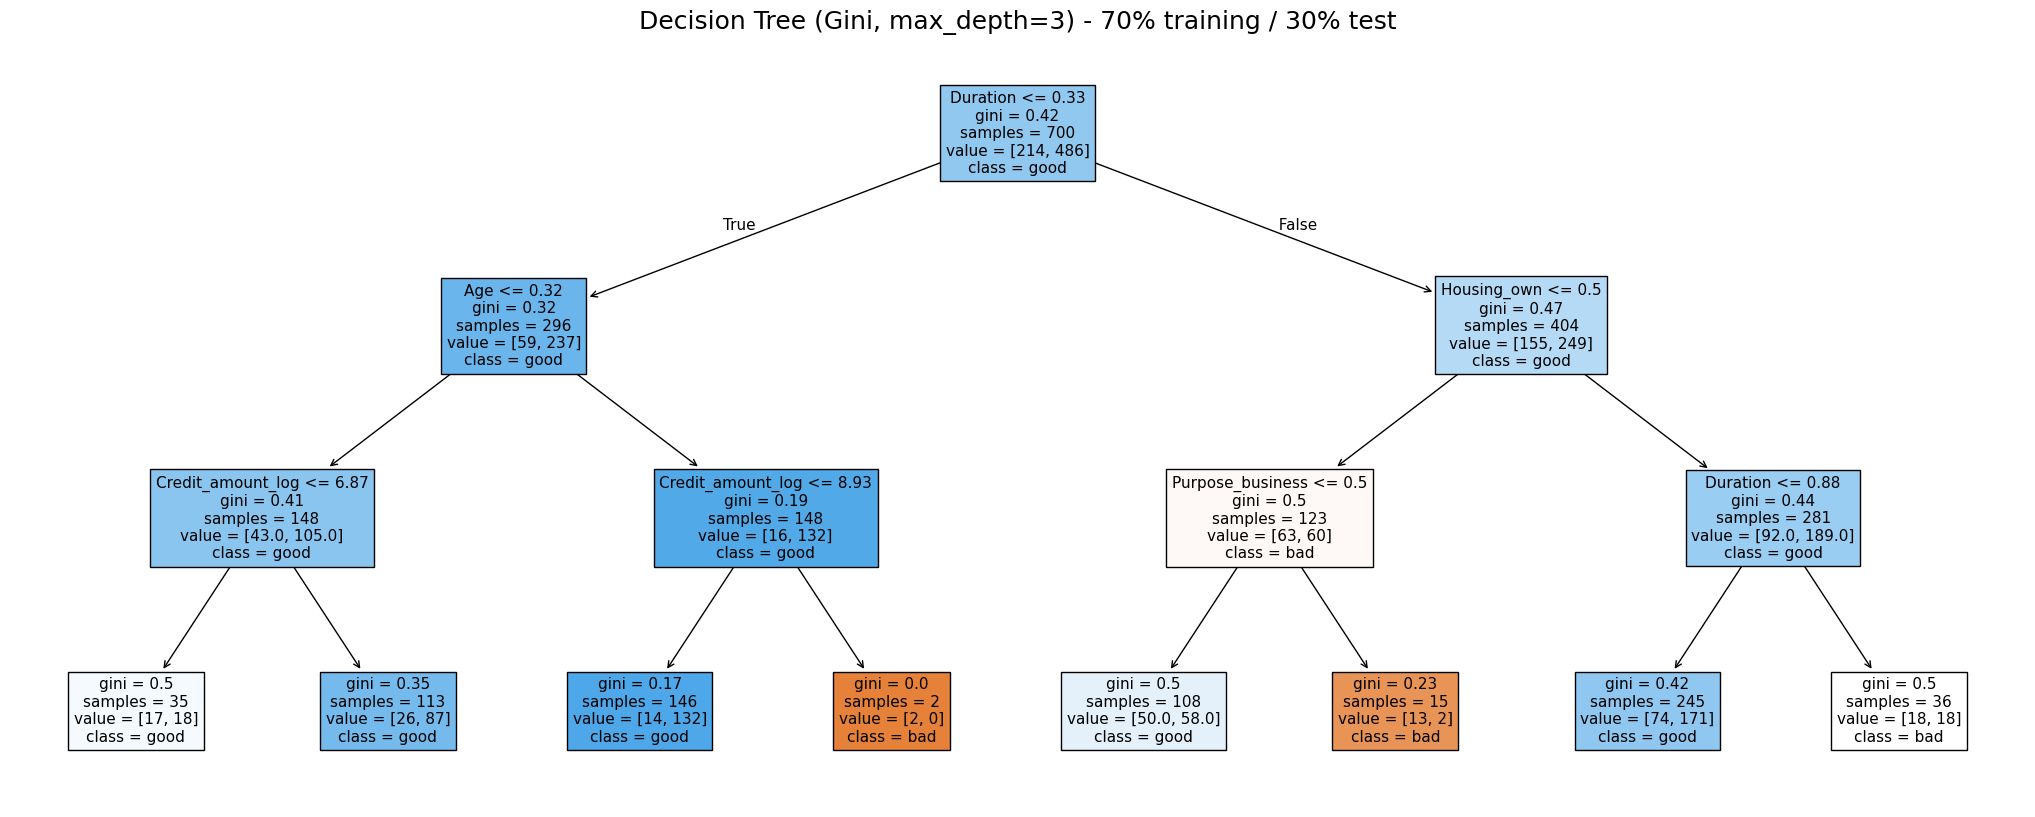

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_70_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_70_plot = clf_70_plot.fit(X_train_70, y_train_70)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_70, clf_70_plot.predict(X_test_70)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_70_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 70% training / 30% test", fontsize=18)
fig.savefig('gini_DT_70_30.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

### Gini index – accuracy summary table


In [ ]:
gini_table = pd.DataFrame(
    [[round(acc_90, 4), round(acc_80, 4), round(acc_70, 4)]],
    index=["Accuracy"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
gini_table

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy,0.64,0.66,0.6233


## Classification – Information Gain (Entropy)

The second attribute selection measure is **Information Gain (IG)**, based on entropy.

- **Entropy** measures the impurity of a node: $Entropy(D) = -\sum_{i=1}^{m} p_i \log_2(p_i)$
- **Information Gain** of attribute A: $Gain(A) = Entropy(D) - \sum_{j=1}^{v} \frac{|D_j|}{|D|} \times Entropy(D_j)$
- At each node, the tree chooses the attribute with the **highest information gain**: the split that reduces the uncertainty about the class (good / bad) the most.

We use `DecisionTreeClassifier(criterion="entropy")` with the **same settings as the Gini section** (same features, `random_state=1`, same three partitions), so the only difference between the two models is the attribute selection measure.


## Classification – Information Gain (Entropy): 90% training / 10% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)   # 90% training and 10% test

# Create Decision Tree classifier object using Information Gain
clf_90_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_90_e = clf_90_e.fit(X_train_90, y_train_90)

# Predict the response for test dataset
y_pred_90_e = clf_90_e.predict(X_test_90)

# Model Accuracy, how often is the classifier correct?
acc_90_e = metrics.accuracy_score(y_test_90, y_pred_90_e)
print("Accuracy:", acc_90_e)

Accuracy: 0.6


### Confusion matrix (90/10)

[[10 20]
 [20 50]]


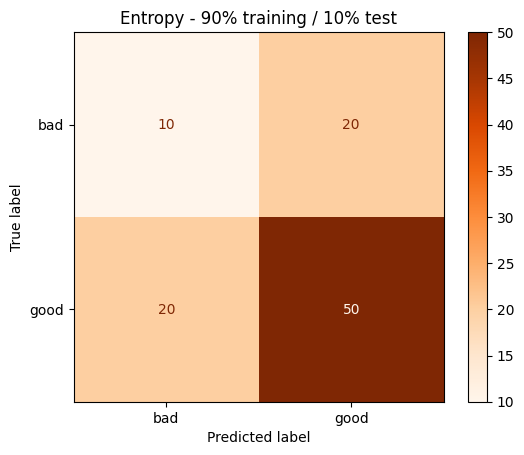

In [ ]:
# Compute and print the confusion matrix
cm_90_e = confusion_matrix(y_test_90, y_pred_90_e)
print(cm_90_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_90_e, X_test_90, y_test_90, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 90% training / 10% test")
plt.show()

### Decision tree plot (90/10)

Accuracy of the pruned tree (for the plot only): 0.7


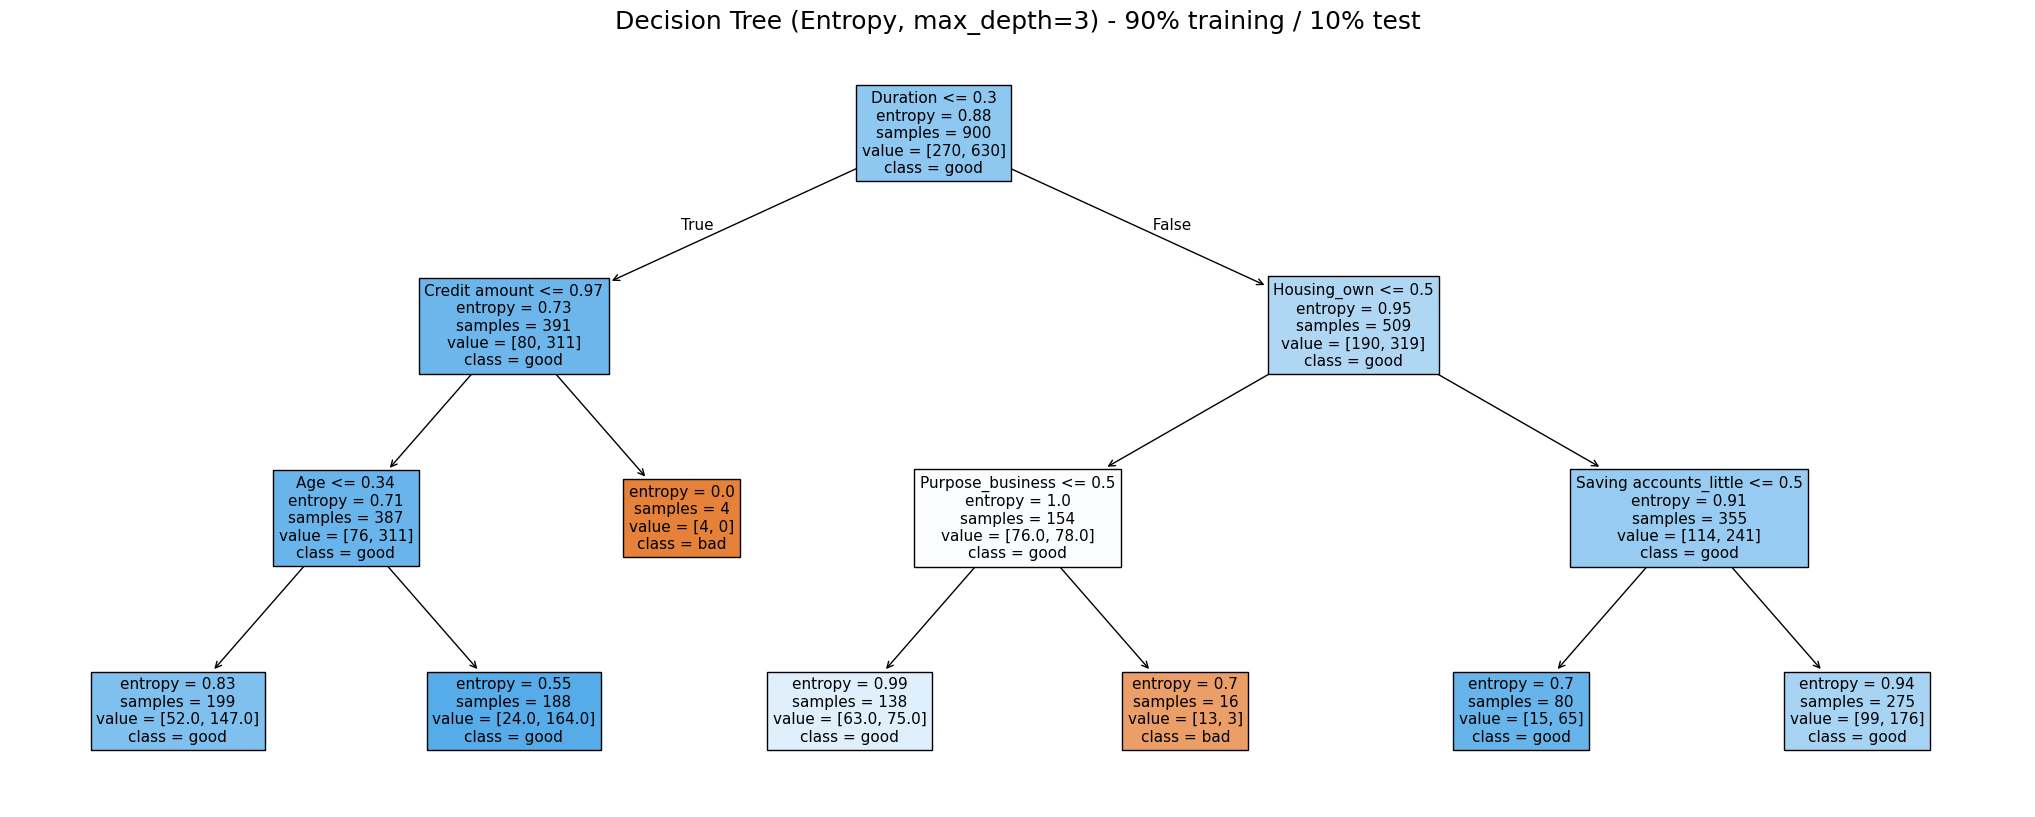

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_90_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_90_e_plot = clf_90_e_plot.fit(X_train_90, y_train_90)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_90, clf_90_e_plot.predict(X_test_90)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_90_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 90% training / 10% test", fontsize=18)
fig.savefig('entropy_DT_90_10.png', dpi=300, bbox_inches='tight')
plt.show()

## Classification – Information Gain (Entropy): 80% training / 20% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)   # 80% training and 20% test

# Create Decision Tree classifier object using Information Gain
clf_80_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_80_e = clf_80_e.fit(X_train_80, y_train_80)

# Predict the response for test dataset
y_pred_80_e = clf_80_e.predict(X_test_80)

# Model Accuracy, how often is the classifier correct?
acc_80_e = metrics.accuracy_score(y_test_80, y_pred_80_e)
print("Accuracy:", acc_80_e)

Accuracy: 0.585


### Confusion matrix (80/20)

[[19 40]
 [43 98]]


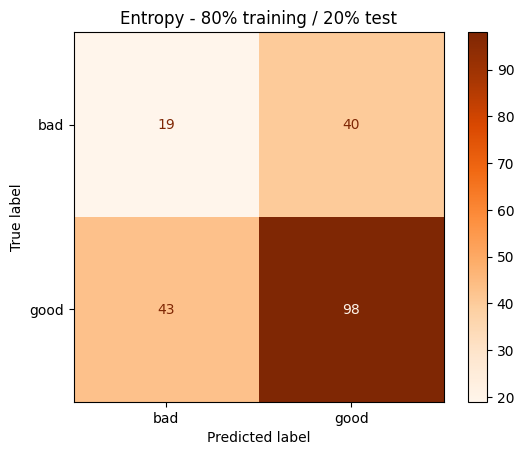

In [ ]:
# Compute and print the confusion matrix
cm_80_e = confusion_matrix(y_test_80, y_pred_80_e)
print(cm_80_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_80_e, X_test_80, y_test_80, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 80% training / 20% test")
plt.show()

### Decision tree plot (80/20)

Accuracy of the pruned tree (for the plot only): 0.71


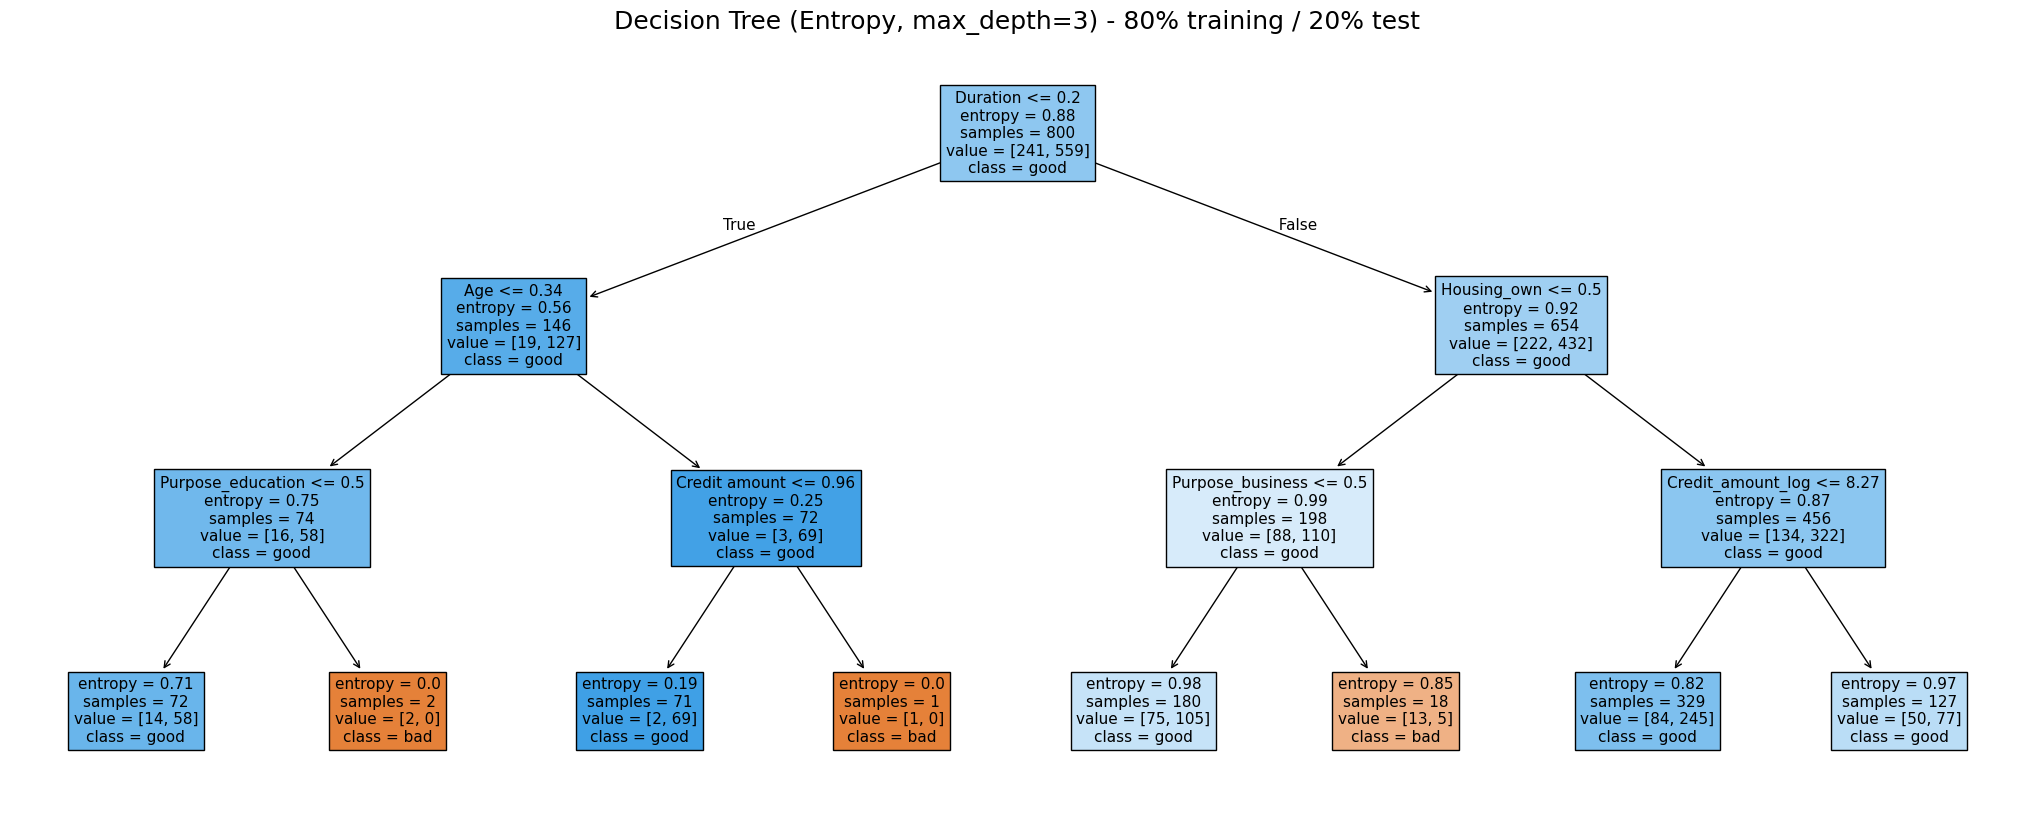

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_80_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_80_e_plot = clf_80_e_plot.fit(X_train_80, y_train_80)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_80, clf_80_e_plot.predict(X_test_80)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_80_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 80% training / 20% test", fontsize=18)
fig.savefig('entropy_DT_80_20.png', dpi=300, bbox_inches='tight')
plt.show()

## Classification – Information Gain (Entropy): 70% training / 30% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)   # 70% training and 30% test

# Create Decision Tree classifier object using Information Gain
clf_70_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_70_e = clf_70_e.fit(X_train_70, y_train_70)

# Predict the response for test dataset
y_pred_70_e = clf_70_e.predict(X_test_70)

# Model Accuracy, how often is the classifier correct?
acc_70_e = metrics.accuracy_score(y_test_70, y_pred_70_e)
print("Accuracy:", acc_70_e)

Accuracy: 0.6366666666666667


### Confusion matrix (70/30)

[[ 37  49]
 [ 60 154]]


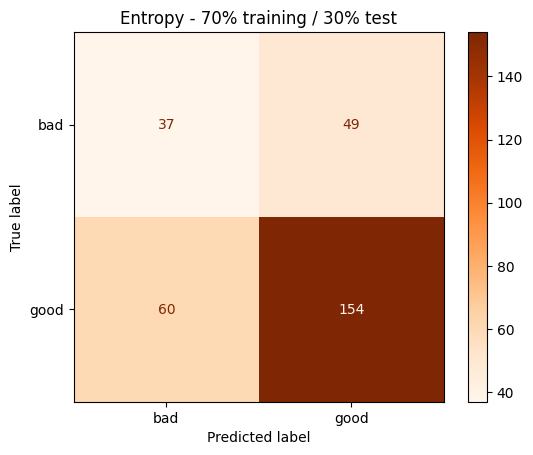

In [ ]:
# Compute and print the confusion matrix
cm_70_e = confusion_matrix(y_test_70, y_pred_70_e)
print(cm_70_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_70_e, X_test_70, y_test_70, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 70% training / 30% test")
plt.show()

### Decision tree plot (70/30)

Accuracy of the pruned tree (for the plot only): 0.7


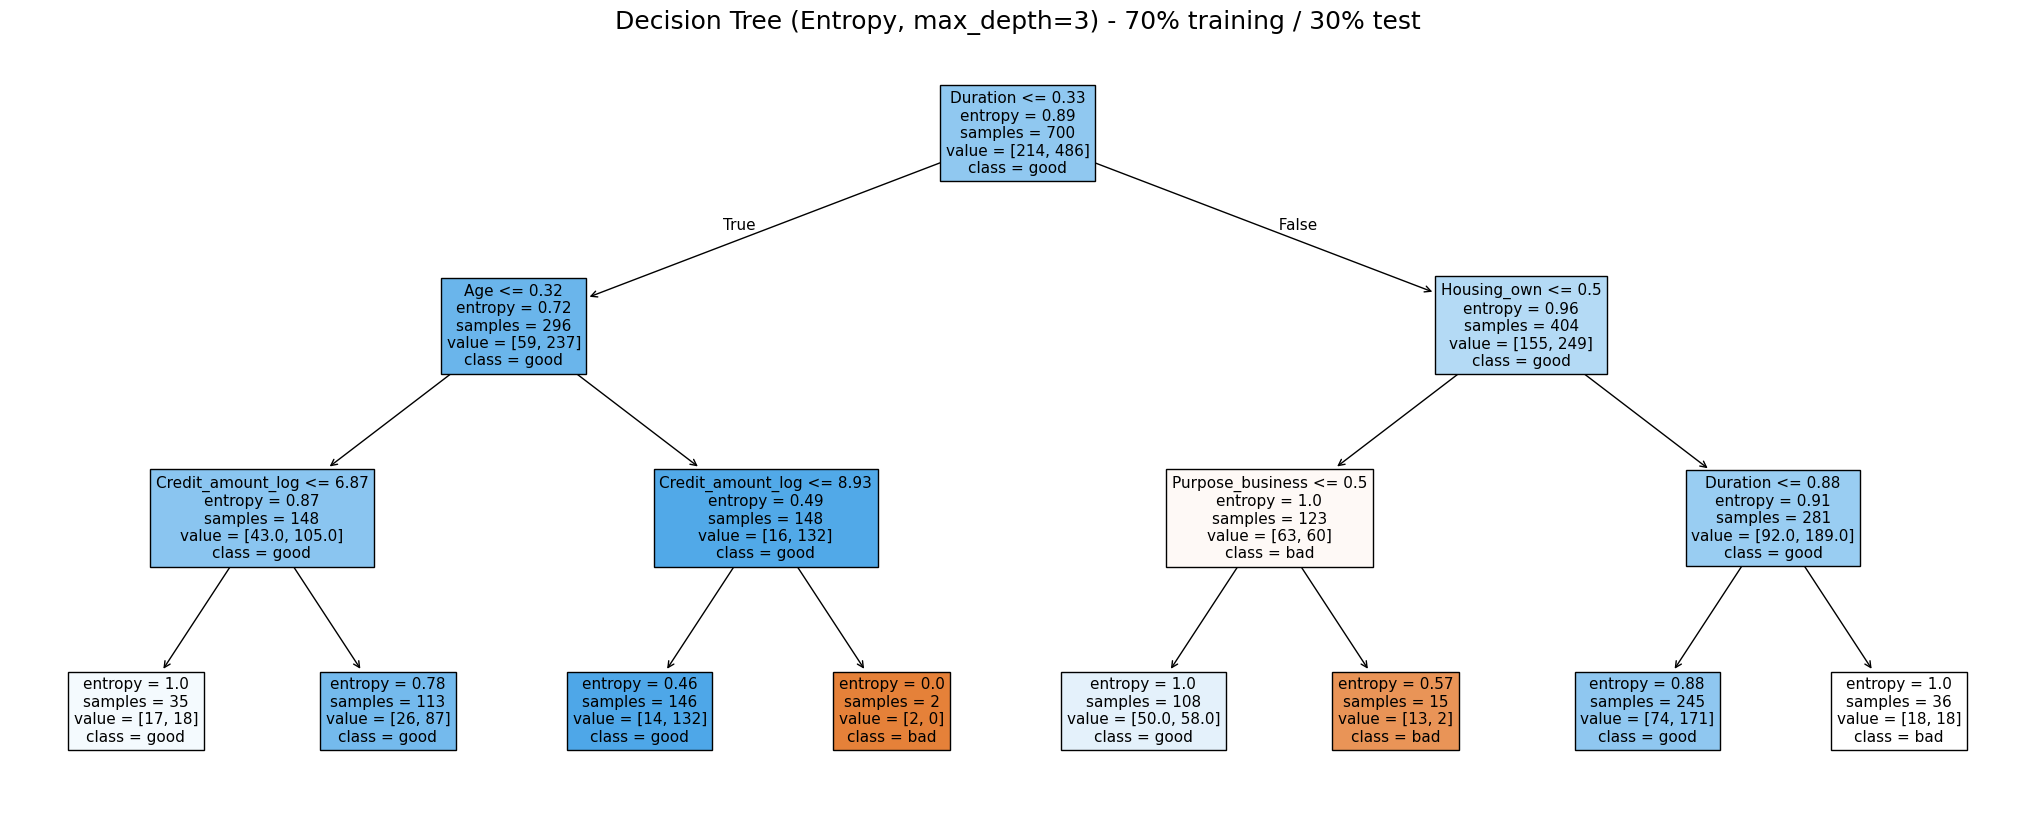

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_70_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_70_e_plot = clf_70_e_plot.fit(X_train_70, y_train_70)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_70, clf_70_e_plot.predict(X_test_70)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_70_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 70% training / 30% test", fontsize=18)
fig.savefig('entropy_DT_70_30.png', dpi=300, bbox_inches='tight')
plt.show()

### Information Gain (Entropy) – accuracy summary table

In [ ]:
entropy_table = pd.DataFrame(
    [[round(acc_90_e, 4), round(acc_80_e, 4), round(acc_70_e, 4)]],
    index=["Accuracy"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
entropy_table

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy,0.6,0.585,0.6367


## [6] Evaluation and Comparison – Classification

In [ ]:
# Accuracy of both attribute selection measures for all partitions
comparison = pd.DataFrame(
    [[acc_90_e, acc_80_e, acc_70_e],
     [acc_90,   acc_80,   acc_70]],
    index=["IG (Entropy)", "Gini index"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
comparison["Average"] = comparison.mean(axis=1)
comparison.round(4)

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set,Average
IG (Entropy),0.60,0.585,0.6367,0.6072
Gini index,0.64,0.660,0.6233,0.6411


In [ ]:
# Best measure for each partition and overall
for split in comparison.columns[:3]:
    print(f"{split}: best = {comparison[split].idxmax()} ({comparison[split].max():.2%})")
print(f"\nBest overall (average accuracy): {comparison['Average'].idxmax()} ({comparison['Average'].max():.2%})")

90% training set 10% testing set: best = Gini index (64.00%)
80% training set 20% testing set: best = Gini index (66.00%)
70% training set 30% testing set: best = IG (Entropy) (63.67%)

Best overall (average accuracy): Gini index (64.11%)


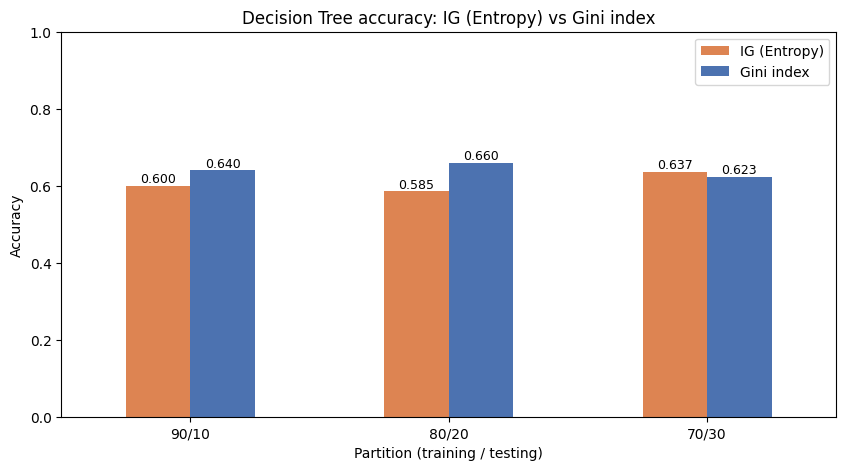

In [ ]:
# Visual comparison of accuracy
ax = comparison.drop(columns="Average").T.plot(kind="bar", figsize=(10, 5), rot=0, color=["#DD8452", "#4C72B0"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_xticklabels(["90/10", "80/20", "70/30"])
ax.set_xlabel("Partition (training / testing)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Decision Tree accuracy: IG (Entropy) vs Gini index")
plt.show()

**IG (Entropy):**

| | 90% training set 10% testing set | 80% training set 20% testing set | 70% training set 30% testing set |
|---|---|---|---|
| Accuracy | 60.00% | 58.50% | 63.67% |

**Gini index:**

| | 90% training set 10% testing set | 80% training set 20% testing set | 70% training set 30% testing set |
|---|---|---|---|
| Accuracy | 64.00% | 66.00% | 62.33% |

**Confusion matrices – bad customers detected (out of all actual bad customers in the test set):**

| Split | Entropy | Gini |
|---|---|---|
| 90/10 | 10 / 30 | 13 / 30 |
| 80/20 | 19 / 59 | 26 / 59 |
| 70/30 | 37 / 86 | 34 / 86 |

**Best per partition:**
- **90/10:** Gini (64.00% vs 60.00%), and it also detects more bad customers (13 vs 10).
- **80/20:** Gini (66.00% vs 58.50%), and it also detects more bad customers (26 vs 19).
- **70/30:** Entropy (63.67% vs 62.33%), and it also detects more bad customers (37 vs 34).

**Best overall:** **Gini index**, with an average accuracy of **64.11%** vs **60.72%** for Entropy, winning two of the three partitions.

**Discussion:**
- The two measures give close results because both estimate node impurity in a similar way. They mostly choose the same attributes near the root of the tree and differ in the lower levels, where few records remain and small differences change the predictions.
- The model with higher accuracy also detected more bad customers in every partition, so accuracy and the confusion matrix agree on the winner.
- The dataset is imbalanced (70% good / 30% bad), so a model that always predicts "good" would reach about 70% accuracy. Both full trees are below this level, which means accuracy alone is not enough to judge them; the confusion matrix shows that both models miss more than half of the bad customers, which is the costliest error for a bank.

In [ ]:
# Overfitting check: training vs testing accuracy of the full trees
fit_check = pd.DataFrame({
    "Model": ["Entropy 90/10", "Entropy 80/20", "Entropy 70/30", "Gini 90/10", "Gini 80/20", "Gini 70/30"],
    "Tree depth": [m.get_depth() for m in [clf_90_e, clf_80_e, clf_70_e, clf_90, clf_80, clf_70]],
    "Leaves": [m.get_n_leaves() for m in [clf_90_e, clf_80_e, clf_70_e, clf_90, clf_80, clf_70]],
    "Training accuracy": [clf_90_e.score(X_train_90, y_train_90), clf_80_e.score(X_train_80, y_train_80), clf_70_e.score(X_train_70, y_train_70),
                          clf_90.score(X_train_90, y_train_90),   clf_80.score(X_train_80, y_train_80),   clf_70.score(X_train_70, y_train_70)],
    "Testing accuracy": [acc_90_e, acc_80_e, acc_70_e, acc_90, acc_80, acc_70]})
fit_check.round(4)

,Model,Tree depth,Leaves,Training accuracy,Testing accuracy
0,Entropy 90/10,19,232,1.0,0.6000
1,Entropy 80/20,22,205,1.0,0.5850
2,Entropy 70/30,20,178,1.0,0.6367
3,Gini 90/10,16,228,1.0,0.6400
4,Gini 80/20,15,206,1.0,0.6600
5,Gini 70/30,20,182,1.0,0.6233


**Overfitting:** the full trees reach **100% training accuracy** with a depth of about 20, but only 58–66% on the testing data. The trees memorize the training records instead of learning general rules, which explains why both measures stay below the 70% baseline and why the results do not improve steadily as the training set grows.

#Clustering

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/Preprocessed_data.csv"

df = pd.read_csv(url)

# Checking that the dataset loaded
print(df.shape)
display(df.head())

(1000, 12)


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit_amount_log
0,0,1.000000,male,2,own,little,little,0.120408,0.052632,radio/TV,good,7.064759
1,1,0.065934,female,2,own,little,moderate,0.746950,1.000000,radio/TV,bad,8.691483
2,2,0.659341,male,1,own,little,little,0.241864,0.210526,education,good,7.648263
3,3,0.571429,male,2,free,little,little,0.999951,1.000000,furniture/equipment,good,8.972464
4,4,0.747253,male,2,free,little,little,0.605316,0.526316,car,bad,8.491055


###Preparing Data For Clustering

In [3]:
# Remove the class label and index column
X = df.drop(columns=["Risk", "Unnamed: 0"], errors="ignore")

# Convert categorical columns into numbers
X = pd.get_dummies(X, dtype=int)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared successfully")
print("Shape:", X_scaled.shape)

Data prepared successfully
Shape: (1000, 25)


###Calculate WSS For Different K Values

In [4]:
wss = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wss.append(kmeans.inertia_)
    wss_table = pd.DataFrame({
    "K": list(K_range),
    "WSS": wss
})
display(wss_table.round(2))

,K,WSS
0,1,25000.00
1,2,22834.73
2,3,21259.01
3,4,20148.98
4,5,19027.57
5,6,18252.46
6,7,17104.29
7,8,16473.35
8,9,15741.95
9,10,14735.25


###Elpow plot

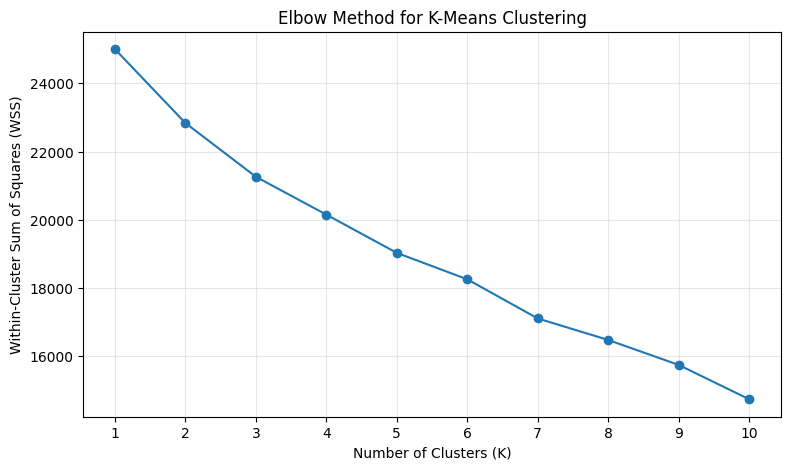

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(
    list(K_range),
    wss,
    marker="o",
    linestyle="-"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WSS)")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(K_range))
plt.grid(True, alpha=0.3)
plt.show()


The results show that WSS decreases as K increases. The largest improvements occur at the beginning of the graph, but there is no clear elbow point.

Therefore, K = 2, K = 3, and K = 4 were selected for further evaluation because they represent the early region where WSS decreases significantly. These values will be compared using the Silhouette Coefficient to help determine the optimal number of clusters.

##[5]K-Means Clustering

K-Means is an unsupervised learning algorithm that divides data into K groups (clusters) based on their similarities. Each group contains data points that have similar characteristics.

The algorithm works by selecting K cluster centers (centroids), assigning each data point to the nearest center, and updating the centers until the clusters become stable.

In our project, K-Means is used to group customers with similar credit characteristics. The Risk column is removed because clustering does not use class labels.

We use the KMeans method from the sklearn.cluster library. The Elbow Method is used to help choose a suitable number of clusters (K) by comparing the Within-Cluster Sum of Squares (WSS) for different K values.